In [16]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

from math import asin,radians,sin, cos, sqrt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error , root_mean_squared_error

In [2]:
df = pd.read_csv(r"D:\ML Datasets\uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [7]:
df = df.drop(["Unnamed: 0", "key"], axis = 1,errors = "ignore")
df = df.dropna()

In [8]:
df.columns

Index(['fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude',
       'dropoff_longitude', 'dropoff_latitude', 'passenger_count'],
      dtype='object')

In [10]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'],errors = "coerce", utc=True)
df = df.dropna()

In [13]:
# Extracthours , day month, year 
df["hour"] = df['pickup_datetime'].dt.hour
df["day"]= df['pickup_datetime'].dt.day
df["month"] = df['pickup_datetime'].dt.month
df["year"] = df['pickup_datetime'].dt.year

In [14]:
df = df.drop('pickup_datetime',axis=1)

In [15]:
df = df[df["fare_amount"]> 0]

In [17]:
def distance(lat1,lon1,lat2,lon2):
    lat1 = radians(lat1)
    lat2 = radians(lat2)
    lon1 = radians(lon1)
    lon2 = radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    # Haversine Formula
    a = sin(dlat/2)**2 + cos(lat1)*cos(lat2)*sin(dlon/2)**2

    c = 2* asin(sqrt(a))
    return 6400 * c

In [18]:
df["distance"] = df.apply(
    lambda row: distance(
        row['pickup_latitude'],
        row["pickup_longitude"],
        row['dropoff_latitude'],
        row['dropoff_longitude']
    ), axis = 1
)

In [22]:
df = df[df['pickup_latitude'].between(-90, 90) &
        df['pickup_longitude'].between(-180, 180) &
        df['dropoff_latitude'].between(-90,90) &
        df['dropoff_longitude'].between(-180,180) &
        (df["distance"] > 0) & 
        (df["passenger_count"] > 0) ].copy()

In [23]:
print("\nCleaned Data ")
df.head()


Cleaned Data 


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,distance
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,1.690985
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,2.468777
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,5.059302
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,1.669247
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,4.495822


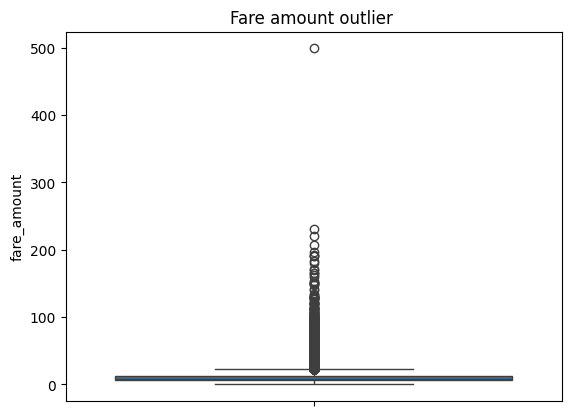

In [24]:
# Show outliers
sns.boxplot(data = df["fare_amount"])
plt.title("Fare amount outlier ")
plt.show()

In [26]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1



In [27]:
df= df[(df["fare_amount"] >= Q1 - 1.5*IQR) &
        (df["fare_amount"] <= Q3 + 1.5*IQR )]

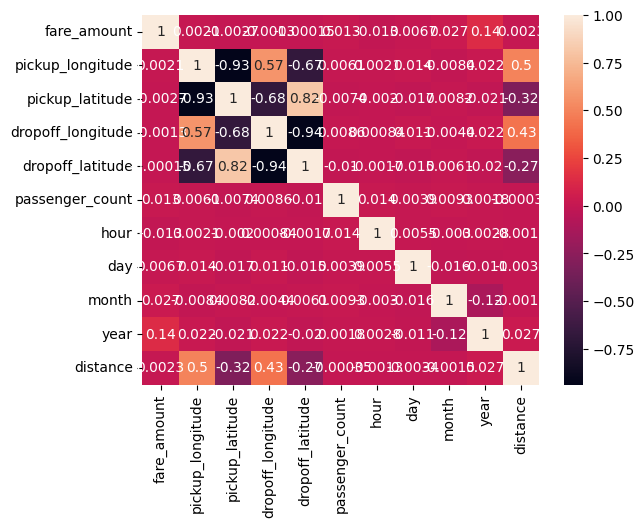

In [37]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

plt.show()

In [38]:
X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [40]:
lr = LinearRegression()
lr.fit(X_train, y_train)

p1 = lr.predict(X_test)

In [42]:
rf = RandomForestRegressor(n_estimators=10)
rf.fit(X_train, y_train)
p2 = rf.predict(X_test)

In [46]:
print("\nLinear Regression")
print("R2 Score:", r2_score(y_test, p1))
print("RMSE:", root_mean_squared_error(y_test, p1))

print("\nRandom Forest Regression")
print("R2 Score:", r2_score(y_test, p2))
print("RMSE:", root_mean_squared_error(y_test, p2))


Linear Regression
R2 Score: 0.0216695693148361
RMSE: 4.11479105803543

Random Forest Regression
R2 Score: 0.7519597186321523
RMSE: 2.0718872310428735


In [47]:
print("\nModel Comparison")

print("Linear Regression R2:", r2_score(y_test, p1))
print("Random Forest R2:", r2_score(y_test, p2))


Model Comparison
Linear Regression R2: 0.0216695693148361
Random Forest R2: 0.7519597186321523
